# M13.8 — Descomposición del error de χ_eff entre semillas (val G3)

Pre-registro: `docs/experiments/M13_8_seed_decomposition.md` (4-11-2026, antes de calcular). Solo val G3; sin GPU.

Entradas (solo lectura), en `<data_root>/results/M13_3/<tag>/val_predictions_embeddings.npz` de 6a-aug s123/s124,
4a-aug s123/s124, 4b-aug s123 y 4c-aug s123 (tags de `MODEL_SPECS` de `M13_6_evaluation`). De cada npz solo se leen
`pred_val, y_val, idx_val` y los metadatos pequeños de comprobación (`y_mean, y_std, label_names, split_path`); `emb_val`
no se lee nunca. Del HDF5 G3 solo `target_network_snr` en las filas de val. Escalador train-only del contrato G1
congelado (`load_contract`). Referencia del GATE: `M13_6_evaluation_summary_20261102_1552.json`.

Convenciones como en `M13_6_evaluation`: etiquetas [chirp_mass, total_mass, chi_eff]; unidades físicas; r = f − θ;
deciles de τ30 newtoniano de la M_c verdadera con bordes de cuantiles de val (D1 = τ más corto). Los IC son bootstrap
emparejado por filas de val (B = 2000, `default_rng(13808)`, un único generador consumido en el orden de las celdas):
miden **muestreo de filas, no variación entre semillas**. Ejecutar de arriba abajo una sola vez (regla de parada).
El resumen se escribe en `<data_root>/results/M13_3/M13_8/M13_8_summary_<UTC>.json` (modo `'x'`).

In [1]:
# 1. Procedencia
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import h5py
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
# Read-only reuse, as in M13_6_evaluation: pinned G1 contract and tau30 of M13.1.
from scripts.m12.m12_5_3_posthoc_check import LABELS, digest, load_contract, npz_to_physical, require
from scripts.m13.m13_1_diagnostics import tau_newtonian

# (key, results tag): same tags as MODEL_SPECS of M13_6_evaluation (cell 1). All six are required here.
MODEL_SPECS = [
    ('6a_aug_s123', 'M13_6a_G3aug_s123'),
    ('6a_aug_s124', 'M13_6a_G3aug_s124'),
    ('4a_aug_s123', 'M13_4a_G3aug_s123'),
    ('4a_aug_s124', 'M13_4a_G3aug_s124'),
    ('4b_aug_s123', 'M13_4b_G3aug_s123'),
    ('4c_aug_s123', 'M13_4c_G3aug_s123'),
]
MODELS = [k for k, _ in MODEL_SPECS]
TAG = dict(MODEL_SPECS)
ARCH_OF = {m: m.rsplit('_s', 1)[0] for m in MODELS}
PAIR_4A, PAIR_6A, M_4B = ('4a_aug_s123', '4a_aug_s124'), ('6a_aug_s123', '6a_aug_s124'), '4b_aug_s123'
WITHIN_PAIRS = [PAIR_4A, PAIR_6A]

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
VAL_NPZ = 'val_predictions_embeddings.npz'
REF_SUMMARY = M13_DIR / 'M13_6_evaluation_summary_20261102_1552.json'
OUT_DIR = M13_DIR / 'M13_8'

# Pre-registered settings (doc M13.8).
N_BOOT = 2000
SEED = 13808
G_THRESHOLD = 0.05                 # primary: G_inf CI vs 5 %
Y_ATOL = 1e-6                      # GATE: max |dy| between models, physical units
REF_RTOL = 1e-6                    # GATE: per-decile RMSE vs M13_6 summary
CHUNK = 100                        # bootstrap replicates per vectorised block (memory only; does not change draws)


def config_of(tag):
    return json.loads((ROOT / 'configs/experiments/m13' / f'train_m{tag[1:]}.json').read_text())


files = {m: M13_DIR / TAG[m] / VAL_NPZ for m in MODELS}
missing = [f'{m}: {p}' for m, p in files.items() if not p.exists()]
require(not missing, f'Missing val npz (required): {missing}')

# Config checks as in M13_6_evaluation cell 3 (shared G3 dataset block, tags, augmentation on).
cfgs = {m: config_of(TAG[m]) for m in MODELS}
ds0 = cfgs[MODELS[0]]['dataset']
require(all(c['dataset'] == ds0 for c in cfgs.values()), 'model configs do not share the G3 dataset block')
for m, c in cfgs.items():
    require(c['outputs']['checkpoint_tag'] == TAG[m], f'{m}: config checkpoint_tag != {TAG[m]}')
    require(bool((c['training'].get('noise_augmentation') or {}).get('enabled', False)), f'{m}: augmentation off')
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=ds0['dataset_id'], file_name=ds0['dataset_file'])
require(G3_H5.exists(), f'Missing G3 HDF5: {G3_H5}')

sha = {m: digest(p) for m, p in files.items()}
prov = pd.DataFrame([dict(model=m, tag=TAG[m], path=str(p), size_mb=p.stat().st_size / 2**20,
                          mtime_utc=datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
                          sha256_short=sha[m][:12]) for m, p in files.items()])
print(DATA_ROOT)
print('G3 HDF5:', G3_H5)
print('reference summary:', REF_SUMMARY, '(exists)' if REF_SUMMARY.exists() else '(NOT FOUND)')
prov

/data/vserrano/cbc_pe_data
G3 HDF5: /data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5
reference summary: /data/vserrano/cbc_pe_data/results/M13_3/M13_6_evaluation_summary_20261102_1552.json (exists)


,model,tag,path,size_mb,mtime_utc,sha256_short
0,6a_aug_s123,M13_6a_G3aug_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_6...,9.955217,2026-10-31T06:50:45+00:00,e4349bb067d2
1,6a_aug_s124,M13_6a_G3aug_s124,/data/vserrano/cbc_pe_data/results/M13_3/M13_6...,9.955836,2026-11-01T15:21:22+00:00,7b44f02a8b8b
2,4a_aug_s123,M13_4a_G3aug_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_4...,9.992407,2026-10-31T07:36:59+00:00,44ff7f540bef
3,4a_aug_s124,M13_4a_G3aug_s124,/data/vserrano/cbc_pe_data/results/M13_3/M13_4...,10.008621,2026-11-01T19:40:06+00:00,c944cae5edb6
4,4b_aug_s123,M13_4b_G3aug_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_4...,9.941967,2026-11-02T09:09:05+00:00,fcb174817f68
5,4c_aug_s123,M13_4c_G3aug_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_4...,9.997837,2026-11-02T12:30:38+00:00,789c57005a79


In [2]:
# 2. Carga (solo pred_val, y_val, idx_val + metadatos de comprobación; emb_val no se lee)
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)', 'model configs: G3 block, tags, augmentation on']


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_pred(path, name):
    # load_pred of M13_6_evaluation (cell 3) without emb_val. NpzFile reads a member only when indexed, so emb_val and
    # the object arrays (model_config, input_normalization) are never decompressed.
    with np.load(path, allow_pickle=False) as a:
        f, y = (a[k].astype(np.float64) for k in ('pred_val', 'y_val'))
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
    n = len(idx)
    check(f.shape == y.shape == (n, 3), f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal M11 train-only label stats')
    check(len(np.unique(idx)) == n, f'{name}: idx without duplicates')
    check(np.isfinite(f).all() and np.isfinite(y).all(), f'{name}: finite values')
    y, f, units = npz_to_physical(y, f, c_mean, c_std)
    check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y ({units})')
    o = np.argsort(idx)                # align every model on the HDF5 row id
    return dict(f=f[o], y=y[o], idx=idx[o], units=units)


val = {m: load_pred(files[m], m) for m in MODELS}
pd.DataFrame([dict(model=m, n=len(v['idx']), units=v['units']) for m, v in val.items()])

,model,n,units
0,6a_aug_s123,40000,standardized
1,6a_aug_s124,40000,standardized
2,4a_aug_s123,40000,standardized
3,4a_aug_s124,40000,standardized
4,4b_aug_s123,40000,standardized
5,4c_aug_s123,40000,standardized


In [3]:
# 3. GATE
REF = MODELS[0]
IDX, Y = val[REF]['idx'], val[REF]['y']
check(np.array_equal(IDX, np.sort(splits['val'])), f'{REF}: idx_val equals val membership')
for m in MODELS:
    check(np.array_equal(val[m]['idx'], IDX), f'{m}: same row_ids as {REF} (after sorting by idx_val)')
    dy = np.abs(val[m]['y'] - Y).max(0)
    print(f'{m}: max |y - y_ref| =', dy)
    check(np.all(dy <= Y_ATOL), f'{m}: same y_true as {REF} (max |dy| <= {Y_ATOL:g})')
P = {m: val[m]['f'] for m in MODELS}
R = {m: P[m] - Y for m in MODELS}        # r = f - theta, physical units, columns in LABELS order
N = len(Y)

# tau30 deciles: identical code to M13_6_evaluation cell 9 (Newtonian tau30 of the TRUE Mc, val quantile edges).
tau30 = tau_newtonian(Y[:, 0])
tau_edges = np.quantile(tau30, np.linspace(0, 1, 11))
tdec = np.clip(np.searchsorted(tau_edges[1:-1], tau30, side='right'), 0, 9)
DEC = [f'D{d + 1}' for d in range(10)]
GROUPS = {**{k: tdec == d for d, k in enumerate(DEC)}, 'D1-D3': tdec <= 2, 'D8-D10': tdec >= 7,
          'global': np.ones(N, bool)}

# Per-decile RMSE of every model and label, recomputed.
rmse_dec = pd.DataFrame([dict(model=m, decile=k, n=int(GROUPS[k].sum()),
                              **dict(zip(LABELS, np.sqrt(np.mean(R[m][GROUPS[k]]**2, 0)))))
                         for k in DEC for m in MODELS])
RM = rmse_dec.set_index(['decile', 'model'])


def rel_ok(a, b):
    return abs(a - b) <= REF_RTOL * abs(b)


ref = json.loads(REF_SUMMARY.read_text()) if REF_SUMMARY.exists() else {}
fails, n_cmp = [], 0
if 'tau_edges_s' in ref:
    check(np.allclose(tau_edges, ref['tau_edges_s'], rtol=REF_RTOL, atol=0), 'tau30 decile edges equal M13_6 summary')
# seed_noise_by_decile.per_model (M13_6 cell 11): per-model chi_eff RMSE and n per tau30 decile.
for row in ref.get('seed_noise_by_decile', {}).get('per_model', []):
    if row.get('grouping') == 'tau30' and row['model'] in MODELS:
        n_cmp += 1
        t = RM.loc[(row['cls'], row['model'])]
        if not (int(t['n']) == row['n'] and rel_ok(t['chi_eff'], row['rmse'])):
            fails.append(('per_model', row['model'], row['cls'], t['chi_eff'], row['rmse']))
# tau_deciles (M13_6 cell 9): rmse_model = mean RMSE over the seeds in 'seeds'; rmse_6a = mean over settings.a6.
a6_ref = ref.get('settings', {}).get('a6') or []
for row in ref.get('tau_deciles', []):
    k, lab, seeds = f"D{row['tau_decile']}", row['label'], row['seeds'].split('+')
    for name, ms, v in (('rmse_model', seeds, row['rmse_model']), ('rmse_6a', a6_ref, row['rmse_6a'])):
        if ms and all(s in MODELS for s in ms):
            n_cmp += 1
            x = np.mean([RM.loc[(k, s), lab] for s in ms])
            if not rel_ok(x, v):
                fails.append((name, '+'.join(ms), k, lab, x, v))
with pd.option_context('display.float_format', '{:.6g}'.format, 'display.width', 200):
    display(rmse_dec.pivot(index='decile', columns='model', values='chi_eff').loc[DEC])
if n_cmp == 0:
    warnings.warn(f'{REF_SUMMARY.name}: no per-decile RMSE to compare; table printed above, check it by hand')
else:
    require(not fails, f'Per-decile RMSE differs from {REF_SUMMARY.name} (rtol {REF_RTOL:g}): {fails[:10]}')
    checks.append(f'per-decile RMSE equals {REF_SUMMARY.name} ({n_cmp} values, rtol {REF_RTOL:g})')

# SNR as in M13_6_evaluation (cell 3 / section 5): target_network_snr of the G3 HDF5 at the sorted val rows.
with h5py.File(G3_H5, 'r') as h:
    require('target_network_snr' in h, 'G3 HDF5 lacks target_network_snr')
    SNR = h['target_network_snr'][IDX].astype(np.float64)
check(np.isfinite(SNR).all() and np.all(SNR > 0), 'target_network_snr finite and positive')
print('n_val:', N, '| decile sizes:', [int(GROUPS[k].sum()) for k in DEC])
print('GATE passed:', len(checks), 'checks')

6a_aug_s123: max |y - y_ref| = [0. 0. 0.]
6a_aug_s124: max |y - y_ref| = [0. 0. 0.]
4a_aug_s123: max |y - y_ref| = [0. 0. 0.]
4a_aug_s124: max |y - y_ref| = [0. 0. 0.]
4b_aug_s123: max |y - y_ref| = [0. 0. 0.]
4c_aug_s123: max |y - y_ref| = [0. 0. 0.]


model,4a_aug_s123,4a_aug_s124,4b_aug_s123,4c_aug_s123,6a_aug_s123,6a_aug_s124
decile,,,,,,
D1,0.182536,0.180892,0.180487,0.181899,0.187894,0.187061
D2,0.168572,0.166606,0.170891,0.170389,0.174694,0.175602
D3,0.163138,0.160958,0.162895,0.161651,0.167434,0.166318
D4,0.154063,0.152774,0.154509,0.152543,0.157935,0.158817
D5,0.152891,0.150399,0.152309,0.150724,0.156864,0.155766
D6,0.145194,0.143681,0.143063,0.144735,0.149157,0.149657
D7,0.149225,0.145778,0.143488,0.144768,0.152917,0.15471
D8,0.151543,0.149748,0.145933,0.148439,0.157,0.156724
D9,0.159037,0.153479,0.150042,0.152259,0.163055,0.162519


n_val: 40000 | decile sizes: [4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000]
GATE passed: 60 checks


In [ ]:
# 4. Funciones y bootstrap
QUANTITIES = ['mse_a', 'mse_b', 'mse_single', 'Ed2', 'dbar', 'Ed2_centr', 'phi', 'G2', 'Ginf', 'common', 'rho_unc',
              'pearson']


def pair_stats(ra, rb):
    # Pre-registered quantities for residuals ra, rb (r = f - theta) on the same rows. Reduces over the last axis, so
    # (replicates, rows) inputs give one value per replicate. Note 1 - phi = common / mse_single: G_inf is nan if common < 0.
    mse_a, mse_b = np.mean(ra**2, -1), np.mean(rb**2, -1)
    mse_single = 0.5 * (mse_a + mse_b)
    d, m = 0.5 * (ra - rb), 0.5 * (ra + rb)
    Ed2 = np.mean(d**2, -1)
    phi = 2.0 * Ed2 / mse_single
    common = np.mean(ra * rb, -1)
    ca, cb = ra - ra.mean(-1, keepdims=True), rb - rb.mean(-1, keepdims=True)
    with np.errstate(invalid='ignore'):
        g_inf = 1.0 - np.sqrt(1.0 - phi)
    return dict(mse_a=mse_a, mse_b=mse_b, mse_single=mse_single, Ed2=Ed2, dbar=np.mean(d, -1), Ed2_centr=np.var(d, -1),
                phi=phi, G2=1.0 - np.sqrt(np.mean(m**2, -1) / mse_single), Ginf=g_inf, common=common,
                rho_unc=common / np.sqrt(mse_a * mse_b),
                pearson=np.mean(ca * cb, -1) / np.sqrt(np.mean(ca**2, -1) * np.mean(cb**2, -1)))


rng = np.random.default_rng(SEED)        # single generator, consumed in cell order (cells 5-11)


def boot(fn, arrays, rows):
    # Point estimate and paired row bootstrap of fn(*arrays) on boolean mask `rows`: one index draw per replicate,
    # shared by every array and every quantity returned by fn. Blocks of CHUNK replicates only bound memory.
    xs = [a[rows] for a in arrays]
    n = len(xs[0])
    point = {k: float(v) for k, v in fn(*xs).items()}
    reps = {k: [] for k in point}
    for s in range(0, N_BOOT, CHUNK):
        ii = rng.integers(0, n, size=(min(CHUNK, N_BOOT - s), n))
        out = fn(*(x[ii] for x in xs))
        for k in reps:
            reps[k].append(out[k])
    return point, {k: np.concatenate(v) for k, v in reps.items()}


def ci(b):
    return np.percentile(b, [2.5, 97.5])  # nan if any replicate is nan (reported as n_nan)


def rows_of(point, reps, **keys):
    return [dict(**keys, quantity=q, value=point[q], ci95_lo=ci(reps[q])[0], ci95_hi=ci(reps[q])[1],
                 n_nan=int(np.isnan(reps[q]).sum())) for q in point]


def wide(t, index='group'):
    w = t.pivot(index=index, columns='quantity', values=['value', 'ci95_lo', 'ci95_hi'])
    w.columns = [q if s == 'value' else f'{q}_{s[5:]}' for s, q in w.columns]
    order = [c for q in t.quantity.unique() for c in (q, f'{q}_lo', f'{q}_hi')]
    return w.loc[t[index].unique(), order]


PAIR_GROUPS = DEC + ['D1-D3', 'D8-D10']


def pair_analysis(pair, label):
    j, (a, b) = LABELS.index(label), pair
    rows, reps = [], {}
    for k in PAIR_GROUPS:
        g = GROUPS[k]
        pt, reps[k] = boot(pair_stats, [R[a][:, j], R[b][:, j]], g)
        rows += rows_of(pt, reps[k], pair=f'{a}/{b}', label=label, group=k, n=int(g.sum()))
    return pd.DataFrame(rows), reps


def s0(tab, reps):
    # D10 and D1-D3 are disjoint row sets, each with its own independent draws from `rng` (pair_analysis):
    # replicate k of one group is independent of replicate k of the other.
    v = tab.set_index(['group', 'quantity']).value
    b = reps['D10']['phi'] - reps['D1-D3']['phi']
    lo, hi = ci(b)
    return dict(pair=tab.pair.iloc[0], label=tab.label.iloc[0], phi_D10=v[('D10', 'phi')],
                phi_D1_D3=v[('D1-D3', 'phi')], diff=v[('D10', 'phi')] - v[('D1-D3', 'phi')], ci95_lo=lo, ci95_hi=hi,
                excludes_0=bool(lo > 0 or hi < 0))


def s1_stats(r4b, ra, rb):
    mse_4b, common = np.mean(r4b**2, -1), np.mean(ra * rb, -1)
    return dict(mse_4b=mse_4b, common_4a=common, delta=mse_4b - common, ratio=mse_4b / common)


def s1(label, groups=('D10', 'D1-D3')):
    j, rows = LABELS.index(label), []
    for k in groups:
        g = GROUPS[k]
        pt, bt = boot(s1_stats, [R[M_4B][:, j], R[PAIR_4A[0]][:, j], R[PAIR_4A[1]][:, j]], g)
        rows += rows_of(pt, bt, label=label, group=k, n=int(g.sum()))
    return pd.DataFrame(rows)

In [ ]:
# 5. Primario: par 4a-aug s123/s124, chi_eff, D1..D10, D1-D3, D8-D10
tab_primary, reps_primary = pair_analysis(PAIR_4A, 'chi_eff')
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 250, 'display.max_columns', 60):
    display(wide(tab_primary))
print('bootstrap replicates with nan:', tab_primary.groupby('quantity').n_nan.sum().to_dict())

In [ ]:
# 6. S0: phi(D10) - phi(D1-D3), par 4a-aug
s0_4a = s0(tab_primary, reps_primary)
pd.Series(s0_4a)

In [ ]:
# 7. S1: mse_4b - common_4a y mse_4b / common_4a, chi_eff, D10 y D1-D3 (bootstrap emparejado de filas)
tab_s1 = s1('chi_eff')
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(wide(tab_s1))

In [ ]:
# 8. S2: matriz 6x6 de rho_unc (chi_eff) en D1, D5, D10 y global; dentro frente a entre arquitecturas
J = LABELS.index('chi_eff')
S2_GROUPS = ['D1', 'D5', 'D10', 'global']
rho_mats, rows_s2 = {}, []
for k in S2_GROUPS:
    g = GROUPS[k]
    M = pd.DataFrame(np.eye(len(MODELS)), index=MODELS, columns=MODELS)
    for i, a in enumerate(MODELS):
        for b in MODELS[i + 1:]:
            M.loc[a, b] = M.loc[b, a] = pair_stats(R[a][g, J], R[b][g, J])['rho_unc']
    rho_mats[k] = M
    between = [M.loc[a, b] for i, a in enumerate(MODELS) for b in MODELS[i + 1:] if ARCH_OF[a] != ARCH_OF[b]]
    rows_s2.append(dict(group=k, n=int(g.sum()), rho_within_4a=M.loc[PAIR_4A], rho_within_6a=M.loc[PAIR_6A],
                        rho_within_mean=np.mean([M.loc[p] for p in WITHIN_PAIRS]), rho_between_mean=np.mean(between),
                        rho_between_min=np.min(between), rho_between_max=np.max(between), n_between=len(between)))
tab_s2 = pd.DataFrame(rows_s2)
with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 200):
    for k, M in rho_mats.items():
        print(k)
        display(M)
    display(tab_s2)

In [ ]:
# 9. S3: terciles de SNR dentro de D10 y de D1-D3 (cortes de val dentro de cada grupo), par 4a-aug, chi_eff
rows_s3, s3_slope = [], {}
a, b = PAIR_4A
for k in ('D10', 'D1-D3'):
    g = GROUPS[k]
    cuts = np.quantile(SNR[g], [1 / 3, 2 / 3])
    ter = np.searchsorted(cuts, SNR, side='right')       # 0, 1, 2; only rows in g are used
    for t in range(3):
        rt = g & (ter == t)
        st = pair_stats(R[a][rt, J], R[b][rt, J])
        rows_s3.append(dict(group=k, tercile=t + 1, n=int(rt.sum()), snr_lo=SNR[rt].min(), snr_hi=SNR[rt].max(),
                            snr_median=np.median(SNR[rt]), common_4a=st['common'], mse_single=st['mse_single']))
    t = [r for r in rows_s3 if r['group'] == k]
    c = np.array([r['common_4a'] for r in t])
    # Descriptive 3-point least-squares fit; undefined if any common <= 0.
    s3_slope[k] = (float(np.polyfit(np.log([r['snr_median'] for r in t]), np.log(c), 1)[0])
                   if np.all(c > 0) else float('nan'))
tab_s3 = pd.DataFrame(rows_s3)
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab_s3)
print('slope d log(common_4a) / d log(SNR median):', s3_slope)

In [ ]:
# 10. S4: celdas 5-6 para el par 6a-aug s123/s124 (chi_eff)
tab_s4, reps_s4 = pair_analysis(PAIR_6A, 'chi_eff')
s0_6a = s0(tab_s4, reps_s4)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 250, 'display.max_columns', 60):
    display(wide(tab_s4))
pd.Series(s0_6a)

In [ ]:
# 11. S5: celdas 5 y 7 para chirp_mass y total_mass
tab_s5, tab_s5_s1 = {}, {}
for lab in ('chirp_mass', 'total_mass'):
    tab_s5[lab], _ = pair_analysis(PAIR_4A, lab)
    tab_s5_s1[lab] = s1(lab)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 250, 'display.max_columns', 60):
    for lab in tab_s5:
        print(lab)
        display(wide(tab_s5[lab]))
        display(wide(tab_s5_s1[lab]))

In [ ]:
# 12. Veredicto del primario (reglas del pre-registro)
p = tab_primary.set_index(['group', 'quantity']).loc[('D10', 'Ginf')]
g_lo, g_hi = float(p.ci95_lo), float(p.ci95_hi)
if g_lo >= G_THRESHOLD:
    verdict = 'varianza relevante'
elif g_hi < G_THRESHOLD:
    verdict = 'varianza secundaria'
else:
    verdict = 'no concluyente'      # includes a nan CI (some replicate with common < 0)
s1_d10 = tab_s1.set_index(['group', 'quantity']).loc[('D10', 'delta')]
readings = dict(
    primary=dict(verdict=verdict, pair='/'.join(PAIR_4A), label='chi_eff', group='D10', Ginf=float(p.value),
                 ci95=[g_lo, g_hi], n_nan=int(p.n_nan), threshold=G_THRESHOLD),
    S0_4a=dict(**s0_4a, reading='inestabilidad específica de señales largas' if s0_4a['excludes_0'] else 'IC incluye 0'),
    S1_D10=dict(delta=float(s1_d10.value), ci95=[float(s1_d10.ci95_lo), float(s1_d10.ci95_hi)],
                reading=('ventaja de 4b no alcanzable promediando 4a' if s1_d10.ci95_hi < 0 else 'IC no queda por debajo de 0')),
    S2=tab_s2[['group', 'rho_within_4a', 'rho_within_mean', 'rho_between_mean']].to_dict('records'),
    S3_slope=s3_slope,
    S0_6a=s0_6a,
)
print(f"PRIMARIO (chi_eff, D10, 4a-aug s123/s124): G_inf = {p.value:.4f} [{g_lo:.4f}, {g_hi:.4f}] -> {verdict.upper()}")
readings

In [ ]:
# 13. Resumen JSON (no sobrescribe: modo 'x')
def to_json(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH = OUT_DIR / f'M13_8_summary_{stamp}.json'
summary = dict(
    experiment='M13.8 seed decomposition of the error (val G3 only)',
    preregistration='docs/experiments/M13_8_seed_decomposition.md (4-11-2026)',
    created_utc=stamp,
    models={m: dict(tag=TAG[m], path=str(files[m]), sha256=sha[m]) for m in MODELS},
    reference_summary=dict(path=str(REF_SUMMARY), exists=REF_SUMMARY.exists(), n_compared=n_cmp),
    g3_hdf5=dict(path=str(G3_H5), columns=['target_network_snr'], rows='val only'),
    contract_identity=identity,
    checks=checks,
    settings=dict(labels=LABELS, residual='f - theta', units='physical (train-only M11 scaler)', n_val=N,
                  n_boot=N_BOOT, seed=SEED, bootstrap='paired row resampling of val: row sampling, not seed variation',
                  rng='single default_rng(13808) consumed in cell order 5-11', y_atol=Y_ATOL, ref_rtol=REF_RTOL,
                  tau_deciles='tau30 Newtonian from true Mc, val quantile edges (M13_6 cell 9)', tau_edges_s=tau_edges,
                  snr='target_network_snr (G3 HDF5); S3 tercile cuts from val rows within each group',
                  pair_4a=PAIR_4A, pair_6a=PAIR_6A, model_4b=M_4B, g_threshold=G_THRESHOLD),
    rmse_by_decile=rmse_dec.to_dict('records'),
    primary=tab_primary.to_dict('records'),
    s0_4a=s0_4a,
    s1_chi_eff=tab_s1.to_dict('records'),
    s2_rho_unc={k: M.to_dict() for k, M in rho_mats.items()},
    s2_summary=tab_s2.to_dict('records'),
    s3=tab_s3.to_dict('records'),
    s3_slope=s3_slope,
    s4_6a=tab_s4.to_dict('records'),
    s4_s0_6a=s0_6a,
    s5={lab: dict(pair=tab_s5[lab].to_dict('records'), s1=tab_s5_s1[lab].to_dict('records')) for lab in tab_s5},
    readings=readings,
)
with open(SUMMARY_PATH, 'x') as fh:
    json.dump(summary, fh, indent=1, default=to_json)
print('saved', SUMMARY_PATH)

## Sección exploratoria (post hoc, 4-11-2026)

**No pre-registrada.** Se escribió después del veredicto pre-registrado (celda 12). No lo modifica ni sirve para elegir
modelos: todo es descriptivo, solo val G3.

**Ejecución:** celdas 1–3 (procedencia, carga, GATE) y después esta sección, de arriba abajo y una sola vez. **NO reejecutar
las celdas 4–13**: se reescribiría el resumen y se consumiría el generador del pre-registro.

- E0 y las figuras F1–F3 salen solo del resumen ya guardado `M13_8_summary_20261104T135215Z.json`.
- E1 y E2 recalculan a partir de los residuos `R` de la celda 3. Tienen su propio generador, `default_rng(13809)`, que se
  consume en orden: primero E1 y después E2.
- E1 (ventana de 4 s frente a τ): no hay un t_merge fijo. Con `truncation_policy = "keep_last_segment"`, una señal de red de
  más de 4 s conserva sus últimos 4 s, hasta el final de la forma de onda (ringdown incluido), y pierde el principio del
  inspiral. Las más cortas se colocan con `random_contained`. El SNR se calcula sobre la parte visible. La forma de onda
  (SEOBNRv4_opt) empieza en 30 Hz. Del HDF5 G3 solo se leen `is_truncated` y `full_network_duration`, en las filas de val.
- E2: ensembles por media simple de predicciones de los modelos existentes.
- E3: guarda `M13_8_exploratory_<UTC>.json` y los PNG en `M13_8/figures/` sin sobrescribir.

In [4]:
# E0. Resumen pre-registrado ya guardado (requiere las celdas 1-3 de esta sesión; no reejecutar 4-13)
import matplotlib.pyplot as plt
from scripts.m13.m13_1_diagnostics import T_SUN

SUMMARY_REF = OUT_DIR / 'M13_8_summary_20261104T135215Z.json'
require(SUMMARY_REF.exists(), f'Missing {SUMMARY_REF}')
S = json.loads(SUMMARY_REF.read_text())
# The saved summary must describe the same npz files, rows and tau deciles as cells 1-3 of this session.
require(all(S['models'][m]['sha256'] == sha[m] for m in MODELS), f'npz sha256 differ from {SUMMARY_REF.name}')
require(S['settings']['n_val'] == N, f'n_val differs from {SUMMARY_REF.name}')
require(np.allclose(S['settings']['tau_edges_s'], tau_edges, rtol=1e-12, atol=0), f'tau edges differ from {SUMMARY_REF.name}')
S_PRIM, S_6A = pd.DataFrame(S['primary']), pd.DataFrame(S['s4_6a'])
S_RMSE, S_S3 = pd.DataFrame(S['rmse_by_decile']), pd.DataFrame(S['s3'])

E_SEED = 13809
rng_e = np.random.default_rng(E_SEED)   # own generator of this section, consumed in order E1 -> E2
J_CHI = LABELS.index('chi_eff')
FIGS = {}


def by_decile(t, q):
    return t[t.quantity == q].set_index('group').loc[DEC]


print(SUMMARY_REF.name, '| sha256', digest(SUMMARY_REF)[:12], '| primary verdict:', S['readings']['primary']['verdict'])

M13_8_summary_20261104T135215Z.json | sha256 3991f1126795 | primary verdict: varianza relevante


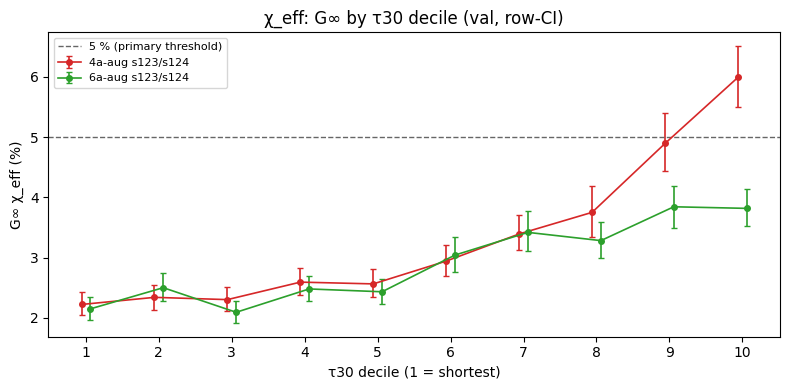

In [5]:
# F1. G_inf (%) de chi_eff por decil de tau30: pares 4a-aug y 6a-aug (IC bootstrap del resumen)
x = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(8, 4))
for k, (name, t, c) in enumerate((('4a-aug s123/s124', S_PRIM, 'tab:red'), ('6a-aug s123/s124', S_6A, 'tab:green'))):
    g = by_decile(t, 'Ginf')
    v, lo, hi = (100.0 * g[col].to_numpy(dtype=float) for col in ('value', 'ci95_lo', 'ci95_hi'))
    ax.errorbar(x + 0.12 * (k - 0.5), v, yerr=[v - lo, hi - v], fmt='o-', ms=4, lw=1.2, capsize=2, color=c, label=name)
ax.axhline(100.0 * G_THRESHOLD, color='0.4', ls='--', lw=1, label=f'{100 * G_THRESHOLD:g} % (primary threshold)')
ax.set(xlabel='τ30 decile (1 = shortest)', ylabel='G∞ χ_eff (%)', xticks=x, title='χ_eff: G∞ by τ30 decile (val, row-CI)')
ax.legend(fontsize=8)
fig.tight_layout()
FIGS['F1_Ginf_by_decile'] = fig
plt.show()

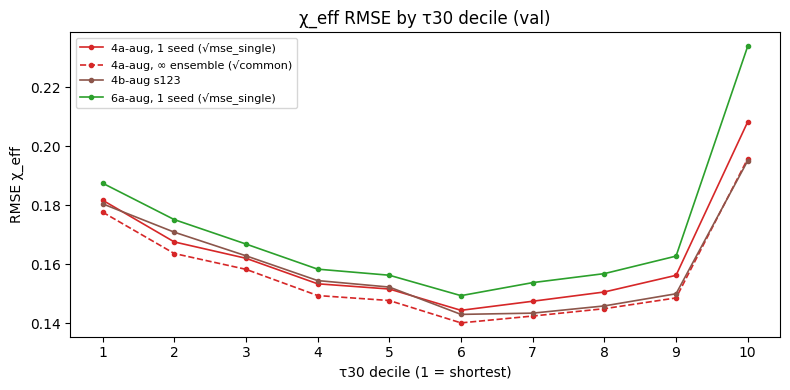

,"4a-aug, 1 seed (√mse_single)","4a-aug, ∞ ensemble (√common)",4b-aug s123,"6a-aug, 1 seed (√mse_single)"
D1,0.181716,0.177676,0.180487,0.187478
D2,0.167592,0.163668,0.170891,0.175149
D3,0.162052,0.158318,0.162895,0.166877
D4,0.153420,0.149440,0.154509,0.158377
D5,0.151650,0.147761,0.152309,0.156316
D6,0.144440,0.140188,0.143063,0.149407
D7,0.147512,0.142506,0.143488,0.153816
D8,0.150648,0.144996,0.145933,0.156862
D9,0.156283,0.148633,0.150042,0.162787
D10,0.208253,0.195774,0.195095,0.233835


In [6]:
# F2. RMSE de chi_eff por decil: 4a 1 semilla, 4a ensemble infinito (sqrt(common)), 4b s123, 6a 1 semilla
with np.errstate(invalid='ignore'):     # sqrt(common) is nan where common < 0
    curves = {'4a-aug, 1 seed (√mse_single)': (np.sqrt(by_decile(S_PRIM, 'mse_single').value.to_numpy(float)), 'tab:red', '-'),
              '4a-aug, ∞ ensemble (√common)': (np.sqrt(by_decile(S_PRIM, 'common').value.to_numpy(float)), 'tab:red', '--'),
              '4b-aug s123': (S_RMSE[S_RMSE.model == M_4B].set_index('decile').loc[DEC, 'chi_eff'].to_numpy(float),
                              'tab:brown', '-'),
              '6a-aug, 1 seed (√mse_single)': (np.sqrt(by_decile(S_6A, 'mse_single').value.to_numpy(float)), 'tab:green', '-')}
fig, ax = plt.subplots(figsize=(8, 4))
for name, (v, c, ls) in curves.items():
    ax.plot(x, v, 'o', ls=ls, ms=3, lw=1.2, color=c, label=name)
ax.set(xlabel='τ30 decile (1 = shortest)', ylabel='RMSE χ_eff', xticks=x, title='χ_eff RMSE by τ30 decile (val)')
ax.legend(fontsize=8)
fig.tight_layout()
FIGS['F2_rmse_by_decile'] = fig
plt.show()
pd.DataFrame({k: v for k, (v, _, _) in curves.items()}, index=DEC)

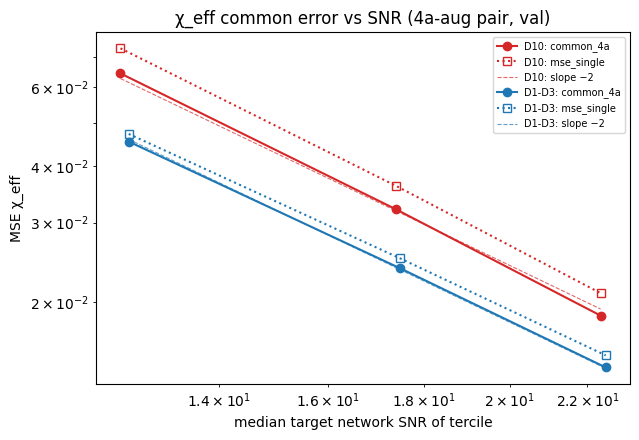

S3 slopes from the saved summary: {'D10': -2.098820384795288, 'D1-D3': -1.970995811888952}


In [7]:
# F3. Bloque s3: common_4a y mse_single frente a la mediana del SNR por tercil (log-log), D10 y D1-D3; referencia -2
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, c in (('D10', 'tab:red'), ('D1-D3', 'tab:blue')):
    t = S_S3[S_S3.group == k].sort_values('tercile')
    s, cm, ms = (t[col].to_numpy(float) for col in ('snr_median', 'common_4a', 'mse_single'))
    ax.plot(s, cm, 'o-', color=c, label=f'{k}: common_4a')
    ax.plot(s, ms, 's:', color=c, mfc='none', label=f'{k}: mse_single')
    # Slope -2 reference through the geometric mean of the common_4a points (shape only, not a fit).
    ok = cm > 0
    if ok.any():
        s0, c0 = np.exp(np.log(s[ok]).mean()), np.exp(np.log(cm[ok]).mean())
        ax.plot(s, c0 * (s / s0)**-2.0, '--', color=c, lw=0.8, alpha=0.7, label=f'{k}: slope −2')
ax.set(xscale='log', yscale='log', xlabel='median target network SNR of tercile', ylabel='MSE χ_eff',
       title='χ_eff common error vs SNR (4a-aug pair, val)')
ax.legend(fontsize=7)
fig.tight_layout()
FIGS['F3_s3_loglog'] = fig
plt.show()
print('S3 slopes from the saved summary:', S['s3_slope'])

rows with is_truncated != (full_network_duration > SEG + 1/4096): 0


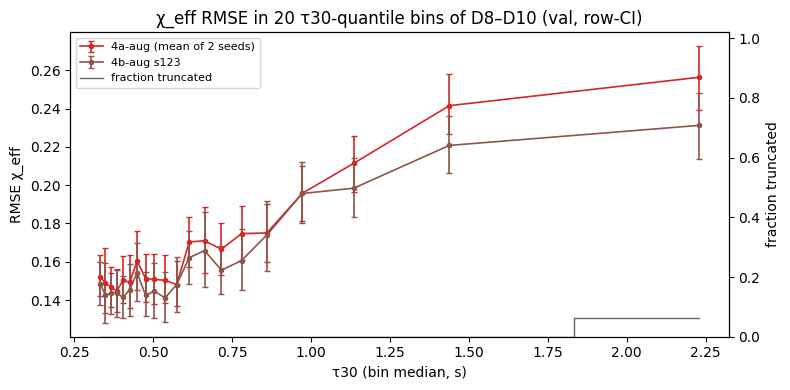

,decile,n,tau30_median,frac_truncated,frac_visible_median,frac_visible_p10,frac_visible_p90,dur_over_tau30_median,n_truncated,f_start_truncated_median_hz
0,D1,4000,0.0686,0,1,1,1,5.593,0,NaN
1,D2,4000,0.08897,0,1,1,1,3.982,0,NaN
2,D3,4000,0.1102,0,1,1,1,3.07,0,NaN
3,D4,4000,0.1358,0,1,1,1,2.432,0,NaN
4,D5,4000,0.1692,0,1,1,1,1.956,0,NaN
5,D6,4000,0.2135,0,1,1,1,1.597,0,NaN
6,D7,4000,0.2797,0,1,1,1,1.317,0,NaN
7,D8,4000,0.38,0,1,1,1,1.13,0,NaN
8,D9,4000,0.5551,0,1,1,1,1.011,0,NaN
9,D10,4000,0.9935,0.0095,1,1,1,0.9756,38,31.07


,bin,n,tau30_lo,tau30_hi,tau30_median,frac_truncated,rmse_4a_mean,rmse_4a_lo,rmse_4a_hi,rmse_4b,rmse_4b_lo,rmse_4b_hi
0,1,600,0.3249,0.3403,0.3319,0,0.1523,0.1421,0.1633,0.1486,0.1377,0.1599
1,2,600,0.3403,0.3565,0.3484,0,0.1488,0.1333,0.1674,0.1426,0.1281,0.1593
2,3,600,0.3565,0.3745,0.3648,0,0.147,0.1366,0.1575,0.1435,0.133,0.1544
3,4,600,0.3745,0.3942,0.3837,0,0.1448,0.1338,0.1557,0.1439,0.1311,0.1564
4,5,600,0.3942,0.4135,0.4041,0,0.1503,0.1382,0.1632,0.1414,0.1305,0.1526
5,6,600,0.4135,0.4367,0.4256,0,0.1494,0.1358,0.1635,0.1455,0.1315,0.1591
6,7,600,0.4367,0.4627,0.449,0,0.1605,0.1452,0.1762,0.1543,0.1398,0.1698
7,8,600,0.4627,0.4885,0.4755,0,0.1513,0.1391,0.164,0.1425,0.1315,0.1545
8,9,600,0.4885,0.5207,0.5032,0,0.1508,0.138,0.164,0.1447,0.1309,0.1591
9,10,600,0.5207,0.5551,0.5374,0,0.1503,0.1383,0.1635,0.1412,0.1286,0.1545


,snr_tercile,truncated,n,snr_median,chi_eff_true_mean,frac_visible_median,rmse_4a_mean,rmse_4b
0,1,True,19,12.57,0.02379,0.8883,0.3029,0.3253
1,1,False,1314,12.41,-0.01458,1,0.2697,0.2518
2,2,True,9,17.92,0.06451,0.8851,0.2446,0.2301
3,2,False,1324,17.4,-0.0009265,1,0.1897,0.1759
4,3,True,10,22.61,0.2577,0.8861,0.2557,0.2419
5,3,False,1324,22.36,0.01256,1,0.1434,0.1371
6,all,True,38,15.45,0.09499,0.8852,0.278,0.2843
7,all,False,3962,17.42,-0.0009483,1,0.2074,0.194


D10: Spearman(full_network_duration / tau30, true chi_eff) = 0.9004 (descriptive)
note: truncated and non-truncated D10 rows differ in the true chi_eff mean (see chi_eff_true_mean): not causal


In [8]:
# E1. Ventana de 4 s frente a tau30 (descriptivo). Truncation facts: src/windowing.py, src/injection.py, src/config.py
# (keep_last_segment: a network signal longer than SEG keeps its last SEG s, ending at the end of the waveform).
TRUNC_KEYS = {'is_truncated', 'full_network_duration'}
SEG = 4.0                              # config.duration [s]
with h5py.File(G3_H5, 'r') as h:       # as SNR in cell 3: only these keys, only the sorted val rows
    miss = sorted(TRUNC_KEYS - set(h.keys()))
    require(not miss, f'G3 HDF5 lacks {miss}')
    TRUNC = h['is_truncated'][IDX].astype(bool)
    FULL_DUR = h['full_network_duration'][IDX].astype(np.float64)
require(np.isfinite(FULL_DUR).all() and np.all(FULL_DUR > 0), 'full_network_duration finite and positive')
n_bad = int(np.sum(TRUNC != (FULL_DUR > SEG + 1.0 / 4096)))
print('rows with is_truncated != (full_network_duration > SEG + 1/4096):', n_bad)
require(n_bad == 0, f'is_truncated inconsistent with full_network_duration in {n_bad} rows')
FRAC_VIS = np.minimum(SEG, FULL_DUR) / FULL_DUR
DUR_RATIO = FULL_DUR / tau30           # SEOBNRv4 network duration vs Newtonian tau30
MC = Y[:, 0]
# Approximate Newtonian frequency SEG s before coalescence (T_vis = SEG, true Mc). Rough bound only: it ignores the merger
# and ringdown that also occupy the window, so the visible inspiral is shorter and the true start frequency is higher.
F_START = (1.0 / np.pi) * (256.0 / 5.0 * SEG)**(-3.0 / 8.0) * (T_SUN * MC)**(-5.0 / 8.0)


def rmse_pair_4b(rows):
    # chi_eff RMSE: 4a-aug as the mean of the two seed RMSEs, and 4b-aug s123 (nan for an empty group).
    if not rows.any():
        return np.nan, np.nan
    e = [np.sqrt(np.mean(R[m][rows, J_CHI]**2)) for m in PAIR_4A + (M_4B,)]
    return 0.5 * (e[0] + e[1]), e[2]


def boot_means(Q, rows):
    # Point means and paired row bootstrap of the columns of Q on mask `rows`, with rng_e: every replicate draws one
    # set of row indices shared by all columns (implemented with resampling counts; same distribution as indexing).
    q = Q[rows]
    n = len(q)
    reps = np.empty((N_BOOT, q.shape[1]))
    for b in range(N_BOOT):
        reps[b] = np.bincount(rng_e.integers(0, n, n), minlength=n) @ q / n
    return q.mean(0), reps


# E1.2-3: per tau30 decile.
rows_e1 = []
for k in DEC:
    g = GROUPS[k]
    gt = g & TRUNC
    rows_e1.append(dict(decile=k, n=int(g.sum()), tau30_median=np.median(tau30[g]), frac_truncated=TRUNC[g].mean(),
                        frac_visible_median=np.median(FRAC_VIS[g]), frac_visible_p10=np.percentile(FRAC_VIS[g], 10),
                        frac_visible_p90=np.percentile(FRAC_VIS[g], 90), dur_over_tau30_median=np.median(DUR_RATIO[g]),
                        n_truncated=int(gt.sum()), f_start_truncated_median_hz=np.median(F_START[gt]) if gt.any() else np.nan))
tab_e1_dec = pd.DataFrame(rows_e1)
g = GROUPS['D10']
spearman_d10 = float(pd.Series(DUR_RATIO[g]).corr(pd.Series(Y[g, J_CHI]), method='spearman'))

# E1.4: 20 tau30-quantile bins inside D8-D10; paired bootstrap of the squared errors (4a s123, 4a s124, 4b).
g = GROUPS['D8-D10']
bin_edges = np.quantile(tau30[g], np.linspace(0, 1, 21))
tbin = np.clip(np.searchsorted(bin_edges[1:-1], tau30, side='right'), 0, 19)
Q = np.column_stack([R[m][:, J_CHI]**2 for m in PAIR_4A + (M_4B,)])
rows_bins = []
for b in range(20):
    gb = g & (tbin == b)
    mp, mb = boot_means(Q, gb)
    r4a, r4a_b = 0.5 * (np.sqrt(mp[0]) + np.sqrt(mp[1])), 0.5 * (np.sqrt(mb[:, 0]) + np.sqrt(mb[:, 1]))
    rows_bins.append(dict(bin=b + 1, n=int(gb.sum()), tau30_lo=bin_edges[b], tau30_hi=bin_edges[b + 1],
                          tau30_median=np.median(tau30[gb]), frac_truncated=TRUNC[gb].mean(),
                          rmse_4a_mean=r4a, rmse_4a_lo=np.percentile(r4a_b, 2.5), rmse_4a_hi=np.percentile(r4a_b, 97.5),
                          rmse_4b=np.sqrt(mp[2]), rmse_4b_lo=np.percentile(np.sqrt(mb[:, 2]), 2.5),
                          rmse_4b_hi=np.percentile(np.sqrt(mb[:, 2]), 97.5)))
tab_e1_bins = pd.DataFrame(rows_bins)

fig, ax = plt.subplots(figsize=(8, 4))
t = tab_e1_bins
for name, col, c in (('4a-aug (mean of 2 seeds)', 'rmse_4a', 'tab:red'), ('4b-aug s123', 'rmse_4b', 'tab:brown')):
    v = t[col if col == 'rmse_4b' else 'rmse_4a_mean'].to_numpy(float)
    ax.errorbar(t.tau30_median, v, yerr=[v - t[f'{col}_lo'], t[f'{col}_hi'] - v], fmt='o-', ms=3, lw=1.2, capsize=2,
                color=c, label=name)
ax.set(xlabel='τ30 (bin median, s)', ylabel='RMSE χ_eff', title='χ_eff RMSE in 20 τ30-quantile bins of D8–D10 (val, row-CI)')
ax2 = ax.twinx()
ax2.step(t.tau30_median, t.frac_truncated, where='mid', color='0.4', lw=1, label='fraction truncated')
ax2.set(ylabel='fraction truncated', ylim=(0, 1.02))
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8)
fig.tight_layout()
FIGS['E1_rmse_tau_bins_D8_D10'] = fig
plt.show()

# E1.5: inside D10, truncated vs not truncated per SNR tercile (D10 cuts computed as in cell 9). The two groups do not
# share the chi_eff prior (aligned spins lengthen the inspiral), so this is descriptive, not causal.
g = GROUPS['D10']
cuts = np.quantile(SNR[g], [1 / 3, 2 / 3])
ter = np.searchsorted(cuts, SNR, side='right')
rows_tr = []
for t_ in [0, 1, 2, None]:
    gt = g if t_ is None else g & (ter == t_)
    for tr in (True, False):
        rr = gt & (TRUNC == tr)
        r4a, r4b = rmse_pair_4b(rr)
        rows_tr.append(dict(snr_tercile='all' if t_ is None else t_ + 1, truncated=tr, n=int(rr.sum()),
                            snr_median=np.median(SNR[rr]) if rr.any() else np.nan,
                            chi_eff_true_mean=Y[rr, J_CHI].mean() if rr.any() else np.nan,
                            frac_visible_median=np.median(FRAC_VIS[rr]) if rr.any() else np.nan,
                            rmse_4a_mean=r4a, rmse_4b=r4b))
tab_e1_d10 = pd.DataFrame(rows_tr)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 250, 'display.max_columns', 40):
    display(tab_e1_dec)
    display(tab_e1_bins)
    display(tab_e1_d10)
print(f'D10: Spearman(full_network_duration / tau30, true chi_eff) = {spearman_d10:.4f} (descriptive)')
print('note: truncated and non-truncated D10 rows differ in the true chi_eff mean (see chi_eff_true_mean): not causal')

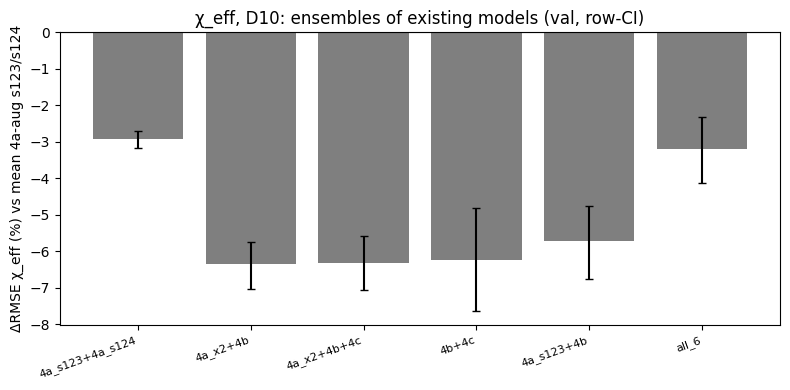

label                   chirp_mass  total_mass  chi_eff
group  ensemble                                        
D1-D3  4a_s123+4a_s124      -1.251      -1.323   -1.134
       4a_s123+4b          -0.8762     -0.9461  -0.7984
       4a_x2+4b             -1.721      -1.845   -1.489
       4a_x2+4b+4c          -2.007       -2.27   -1.679
       4b+4c                -1.376      -1.815  -0.9287
       all_6                -1.252      -1.318  -0.9012
D10    4a_s123+4a_s124      -2.247      -2.406   -2.923
       4a_s123+4b            -3.91      -4.129    -5.73
       4a_x2+4b             -4.436      -4.528   -6.357
       4a_x2+4b+4c           -4.94      -4.584   -6.317
       4b+4c                -4.975      -4.063   -6.227
       all_6                -1.797      -2.914   -3.198
global 4a_s123+4a_s124      -1.346      -1.581   -1.697
       4a_s123+4b           -1.577      -1.865   -2.412
       4a_x2+4b             -2.234      -2.597   -3.047
       4a_x2+4b+4c          -2.589      -3.141   -3.383
       4b+4c                -2.236      -2.829   -3.065
       all_6                -1.825      -2.152   -2.204

,group,label,ensemble,members,n,rmse,rmse_4a_mean,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct
0,global,chirp_mass,4a_s123+4a_s124,4a_aug_s123+4a_aug_s124,40000,4.679,4.743,-1.346,-1.402,-1.292
1,global,chirp_mass,4a_x2+4b,4a_aug_s123+4a_aug_s124+4b_aug_s123,40000,4.637,4.743,-2.234,-2.443,-2.033
2,global,chirp_mass,4a_x2+4b+4c,4a_aug_s123+4a_aug_s124+4b_aug_s123+4c_aug_s123,40000,4.62,4.743,-2.589,-2.83,-2.357
3,global,chirp_mass,4b+4c,4b_aug_s123+4c_aug_s123,40000,4.637,4.743,-2.236,-2.713,-1.768
4,global,chirp_mass,4a_s123+4b,4a_aug_s123+4b_aug_s123,40000,4.668,4.743,-1.577,-1.892,-1.272
5,global,chirp_mass,all_6,6a_aug_s123+6a_aug_s124+4a_aug_s123+4a_aug_s12...,40000,4.656,4.743,-1.825,-2.07,-1.577
6,global,total_mass,4a_s123+4a_s124,4a_aug_s123+4a_aug_s124,40000,8.147,8.278,-1.581,-1.639,-1.526
7,global,total_mass,4a_x2+4b,4a_aug_s123+4a_aug_s124+4b_aug_s123,40000,8.063,8.278,-2.597,-2.781,-2.415
8,global,total_mass,4a_x2+4b+4c,4a_aug_s123+4a_aug_s124+4b_aug_s123+4c_aug_s123,40000,8.018,8.278,-3.141,-3.385,-2.905
9,global,total_mass,4b+4c,4b_aug_s123+4c_aug_s123,40000,8.043,8.278,-2.829,-3.287,-2.377


In [9]:
# E2. Ensembles de modelos existentes (media simple de predicciones; descriptivo). Referencia: media de los RMSE de 4a s123/s124
ENSEMBLES = {
    '4a_s123+4a_s124': ['4a_aug_s123', '4a_aug_s124'],
    '4a_x2+4b': ['4a_aug_s123', '4a_aug_s124', '4b_aug_s123'],
    '4a_x2+4b+4c': ['4a_aug_s123', '4a_aug_s124', '4b_aug_s123', '4c_aug_s123'],
    '4b+4c': ['4b_aug_s123', '4c_aug_s123'],
    '4a_s123+4b': ['4a_aug_s123', '4b_aug_s123'],
    'all_6': list(MODELS),
}
E2_GROUPS = ['global', 'D1-D3', 'D10']
E_RES = {k: np.mean([P[m] for m in ms], 0) - Y for k, ms in ENSEMBLES.items()}
# Columns: for each label, [4a s123, 4a s124, ensembles...] squared errors; one shared index draw per replicate.
NE = 2 + len(ENSEMBLES)
Q2 = np.column_stack([a[:, j]**2 for j in range(len(LABELS))
                      for a in [R[PAIR_4A[0]], R[PAIR_4A[1]]] + list(E_RES.values())])
rows_e2 = []
for k in E2_GROUPS:
    g = GROUPS[k]
    mp, mb = boot_means(Q2, g)
    for j, lab in enumerate(LABELS):
        cp, cb = np.sqrt(mp[j * NE:(j + 1) * NE]), np.sqrt(mb[:, j * NE:(j + 1) * NE])
        ref_p, ref_b = 0.5 * (cp[0] + cp[1]), 0.5 * (cb[:, 0] + cb[:, 1])
        for i, (e, ms) in enumerate(ENSEMBLES.items()):
            d_b = 100.0 * (cb[:, 2 + i] / ref_b - 1.0)
            rows_e2.append(dict(group=k, label=lab, ensemble=e, members='+'.join(ms), n=int(g.sum()), rmse=cp[2 + i],
                                rmse_4a_mean=ref_p, delta_rmse_pct=100.0 * (cp[2 + i] / ref_p - 1.0),
                                ci95_lo_pct=np.percentile(d_b, 2.5), ci95_hi_pct=np.percentile(d_b, 97.5)))
tab_e2 = pd.DataFrame(rows_e2)

t = tab_e2[(tab_e2.group == 'D10') & (tab_e2.label == 'chi_eff')]
fig, ax = plt.subplots(figsize=(8, 4))
xe = np.arange(len(t))
ax.bar(xe, t.delta_rmse_pct, color='tab:gray',
       yerr=[t.delta_rmse_pct - t.ci95_lo_pct, t.ci95_hi_pct - t.delta_rmse_pct], capsize=3)
ax.axhline(0, color='0.3', lw=0.8)
ax.set(xticks=xe, ylabel='ΔRMSE χ_eff (%) vs mean 4a-aug s123/s124',
       title='χ_eff, D10: ensembles of existing models (val, row-CI)')
ax.set_xticklabels(t.ensemble, rotation=20, ha='right', fontsize=8)
fig.tight_layout()
FIGS['E2_ensembles_chi_eff_D10'] = fig
plt.show()
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 250):
    display(tab_e2.set_index(['group', 'ensemble', 'label']).delta_rmse_pct.unstack('label')[LABELS])
    display(tab_e2)

In [10]:
# E3. Guardado: JSON exploratorio (modo 'x') y PNG en OUT_DIR/figures sin sobrescribir (misma marca UTC)
def to_json(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


stamp_e = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
FIG_DIR = OUT_DIR / 'figures'
EXPL_PATH = OUT_DIR / f'M13_8_exploratory_{stamp_e}.json'
fig_paths = {k: FIG_DIR / f'M13_8E_{k}_{stamp_e}.png' for k in FIGS}
clash = [str(p) for p in [EXPL_PATH, *fig_paths.values()] if p.exists()]
require(not clash, f'Refusing to overwrite: {clash}')
FIG_DIR.mkdir(parents=True, exist_ok=True)
for k, fig in FIGS.items():
    fig.savefig(fig_paths[k], dpi=150)
expl = dict(
    experiment='M13.8-E exploratory section (post hoc, NOT pre-registered; val G3 only)',
    note='after the pre-registered verdict; does not modify it and is not used for model selection',
    created_utc=stamp_e,
    summary_ref=dict(path=str(SUMMARY_REF), sha256=digest(SUMMARY_REF), primary_verdict=S['readings']['primary']['verdict']),
    models={m: dict(tag=TAG[m], sha256=sha[m]) for m in MODELS},
    settings=dict(labels=LABELS, residual='f - theta', units='physical', n_val=N, n_boot=N_BOOT, seed=E_SEED,
                  rng='own default_rng(13809), consumed E1 (tau bins) then E2', seg_s=SEG, trunc_keys=sorted(TRUNC_KEYS),
                  trunc_check='is_truncated == (full_network_duration > SEG + 1/4096)',
                  frac_visible='min(SEG, full_network_duration) / full_network_duration',
                  f_start='Newtonian, T_vis = SEG, true Mc; approximate (ignores merger and ringdown in the window)',
                  tau_bins='20 tau30-quantile bins within D8-D10', d10_snr_terciles='val quantiles within D10 (as cell 9)',
                  rmse_4a='mean of the RMSEs of 4a-aug s123 and s124', ensembles=ENSEMBLES,
                  e2_reference='mean of the RMSEs of 4a-aug s123 and s124'),
    f2_curves={k: v for k, (v, _, _) in curves.items()},
    e1_deciles=tab_e1_dec.to_dict('records'),
    e1_spearman_dur_ratio_chi_eff_D10=spearman_d10,
    e1_tau_bins_D8_D10=tab_e1_bins.to_dict('records'),
    e1_D10_truncated_vs_not=tab_e1_d10.to_dict('records'),
    e2_ensembles=tab_e2.to_dict('records'),
    figures={k: str(p) for k, p in fig_paths.items()},
)
with open(EXPL_PATH, 'x') as fh:
    json.dump(expl, fh, indent=1, default=to_json)
print('saved', EXPL_PATH)
for p in fig_paths.values():
    print('saved', p)

saved /data/vserrano/cbc_pe_data/results/M13_3/M13_8/M13_8_exploratory_20261104T142718Z.json
saved /data/vserrano/cbc_pe_data/results/M13_3/M13_8/figures/M13_8E_F1_Ginf_by_decile_20261104T142718Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M13_8/figures/M13_8E_F2_rmse_by_decile_20261104T142718Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M13_8/figures/M13_8E_F3_s3_loglog_20261104T142718Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M13_8/figures/M13_8E_E1_rmse_tau_bins_D8_D10_20261104T142718Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M13_8/figures/M13_8E_E2_ensembles_chi_eff_D10_20261104T142718Z.png
